<a href="https://colab.research.google.com/github/lalitha-630/ai-soc/blob/main/Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q datasets pandas scikit-learn joblib

In [3]:
from datasets import load_dataset
import pandas as pd

dataset = load_dataset("Mireu-Lab/UNSW-NB15")

print(dataset)
print("Available splits:", list(dataset.keys()))

# Combine available splits into one DataFrame
df = pd.concat(
    [dataset[split].to_pandas() for split in dataset.keys()],
    ignore_index=True
)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

README.md:   0%|          | 0.00/1.88k [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B / 15.4MB            

train.csv: downloading bytes:           |  0.00B            

test.csv: reconstructing file:   0%|          |  0.00B / 32.3MB            

test.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/82332 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/175341 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label'],
        num_rows: 82332
    })
    test: Dataset({
        features: ['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', '

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,...,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,...,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,...,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,...,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,...,1,3,0,0,0,2,3,0,Normal,0


In [4]:
# The model predicts label: 0 = Normal, 1 = Attack.
# attack_cat is deliberately excluded from the input features.

target_col = "label"

if target_col not in df.columns:
    raise ValueError(f"Expected target column '{target_col}'. Found: {df.columns.tolist()}")

df = df.dropna(subset=[target_col]).copy()

# Handle either numeric labels or text labels
if not pd.api.types.is_numeric_dtype(df[target_col]):
    label_values = df[target_col].astype(str).str.strip().str.lower()
    label_map = {
        "normal": 0,
        "benign": 0,
        "0": 0,
        "attack": 1,
        "malicious": 1,
        "1": 1
    }
    df[target_col] = label_values.map(label_map)

    if df[target_col].isna().any():
        raise ValueError(
            "Some label values were not recognized. Inspect them with "
            "df['label'].value_counts() and update label_map."
        )

df[target_col] = df[target_col].astype(int)

# Remove target, attack category, and identifiers/non-feature metadata
drop_cols = ["label", "attack_cat", "id", "split"]
X = df.drop(columns=[c for c in drop_cols if c in df.columns]).copy()
y = df[target_col].copy()

# Clean column names and make sure feature values are usable
X.columns = X.columns.astype(str)
X = X.replace([float("inf"), float("-inf")], pd.NA)

print("Feature count:", X.shape[1])
print("Label counts:")
print(y.value_counts())
print("Feature columns:")
print(X.columns.tolist())

Feature count: 42
Label counts:
label
1    164673
0     93000
Name: count, dtype: int64
Feature columns:
['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Split before fitting preprocessing, so the test data does not influence training.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

categorical_cols = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_cols = [c for c in X_train.columns if c not in categorical_cols]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced_subsample",
        n_jobs=-1
    ))
])

pipeline.fit(X_train, y_train)
print("Training complete.")

Training complete.


In [6]:
y_pred = pipeline.predict(X_test)
y_prob = pipeline.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Attack"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

              precision    recall  f1-score   support

      Normal       0.93      0.93      0.93     18600
      Attack       0.96      0.96      0.96     32935

    accuracy                           0.95     51535
   macro avg       0.95      0.95      0.95     51535
weighted avg       0.95      0.95      0.95     51535

Confusion matrix:
[[17367  1233]
 [ 1290 31645]]
ROC-AUC: 0.992


In [7]:
import joblib
from pathlib import Path

artifact = {
    "pipeline": pipeline,
    "feature_columns": X.columns.tolist(),
    "target_name": "label",
    "label_map": {0: "Normal", 1: "Attack"},
    "dataset_name": "Mireu-Lab/UNSW-NB15"
}

model_path = Path("model_bundle.joblib")
joblib.dump(artifact, model_path)

print(f"Saved: {model_path.resolve()}")

Saved: /content/model_bundle.joblib


In [11]:
loaded = joblib.load("model_bundle.joblib")
loaded_pipeline = loaded["pipeline"]
feature_columns = loaded["feature_columns"]

# Use a held-out row to verify the saved artifact works
sample = X_test.iloc[[0]][feature_columns]

prediction = int(loaded_pipeline.predict(sample)[0])
attack_score = float(loaded_pipeline.predict_proba(sample)[0][1])

print("Prediction:", loaded["label_map"][prediction])
print("Attack score:", round(attack_score, 4))

Prediction: Attack
Attack score: 0.84


Evaluation metrics
Accuracy : 0.9510
Precision: 0.9625
Recall   : 0.9608
F1-score : 0.9617
ROC-AUC  : 0.9920

Classification report:
              precision    recall  f1-score   support

      Normal       0.93      0.93      0.93     18600
      Attack       0.96      0.96      0.96     32935

    accuracy                           0.95     51535
   macro avg       0.95      0.95      0.95     51535
weighted avg       0.95      0.95      0.95     51535



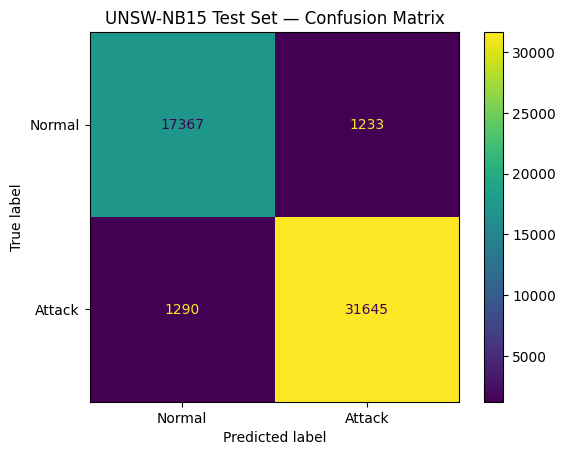

In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predictions on the held-out test set
y_pred = pipeline.predict(X_test)
y_prob = pipeline.predict_proba(X_test)[:, 1]

print("Evaluation metrics")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Normal", "Attack"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Attack"]
)
display.plot()
plt.title("UNSW-NB15 Test Set — Confusion Matrix")
plt.show()